In [1]:
!nvidia-smi

Sat Oct 31 14:58:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip -q install wfdb
!wget -q -O ptbxl.zip https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip
!unzip -q ptbxl.zip -d /content/

In [4]:
!ls /content

drive
ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
ptbxl.zip
sample_data


In [5]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 1  ·  Project configuration            ║
# ╚══════════════════════════════════════════════════════════╝
import os, glob, ast, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
warnings.filterwarnings('ignore')

PROJECT = 'Isoline'
BASE    = '/content/drive/MyDrive/isoline'
PTB     = glob.glob('/content/ptb-xl-*/')[0]
DIRS    = {k: f'{BASE}/{k}' for k in ['data', 'weights', 'results', 'samples']}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
LEADS   = ['I','II','III','AVR','AVL','AVF','V1','V2','V3','V4','V5','V6']
FS, SEED = 100, 42
np.random.seed(SEED)

COLORS = {'NORM':'#2ecc71','MI':'#e74c3c','STTC':'#f39c12','CD':'#3498db','HYP':'#9b59b6'}
plt.rcParams.update({
    'figure.facecolor':'#0f1117', 'axes.facecolor':'#0f1117', 'savefig.facecolor':'#0f1117',
    'axes.edgecolor':'#2a2f3a', 'axes.labelcolor':'#c9d1d9', 'text.color':'#c9d1d9',
    'xtick.color':'#8b949e', 'ytick.color':'#8b949e', 'grid.color':'#1f2430',
    'axes.grid':True, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})

def banner(title, subtitle=''):
    display(HTML(f"""
    <div style="background:linear-gradient(90deg,#0f1117,#1b2333);border-left:5px solid #e74c3c;
                padding:14px 20px;border-radius:8px;margin:6px 0;font-family:sans-serif">
      <div style="color:#e74c3c;font-size:12px;letter-spacing:3px">{PROJECT.upper()}</div>
      <div style="color:#fff;font-size:20px;font-weight:700">{title}</div>
      <div style="color:#8b949e;font-size:13px">{subtitle}</div>
    </div>"""))

banner('Project ready', 'Reads the ECG. Knows when not to.')
print('Dataset :', PTB)
print('Saving to:', BASE)

Dataset : /content/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/
Saving to: /content/drive/MyDrive/isoline


Kept 21,388 of 21,799 records (dropped 411 with no diagnosis)


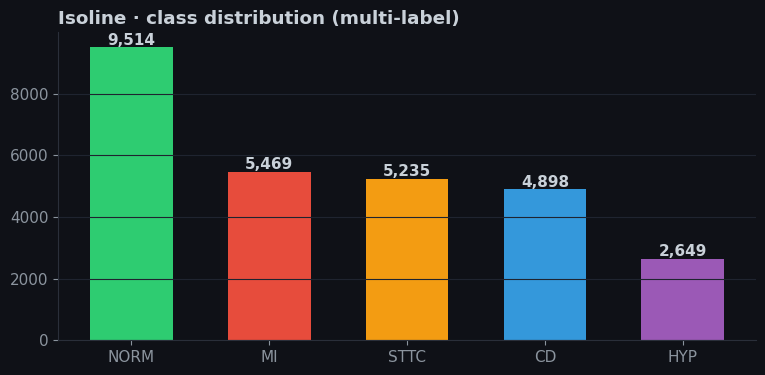

split
train    17084
test      2158
val       2146


In [6]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 2  ·  Labels + official split           ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 2 · Labels', 'Collapsing PTB-XL diagnostic codes into 5 superclasses')

df = pd.read_csv(PTB + 'ptbxl_database.csv', index_col='ecg_id')
df['scp_codes'] = df.scp_codes.apply(ast.literal_eval)

scp = pd.read_csv(PTB + 'scp_statements.csv', index_col=0)
scp = scp[scp.diagnostic == 1]

def to_super(codes):
    return sorted({scp.loc[c, 'diagnostic_class'] for c in codes if c in scp.index})

df['superclass'] = df.scp_codes.apply(to_super)
before = len(df)
df = df[df.superclass.map(len) > 0].copy()          # drop records with no diagnostic label
print(f'Kept {len(df):,} of {before:,} records (dropped {before-len(df):,} with no diagnosis)')

# multi-hot label matrix  (a patient can have more than one condition)
Y = np.zeros((len(df), len(CLASSES)), dtype=np.float32)
for i, labs in enumerate(df.superclass):
    for l in labs:
        Y[i, CLASSES.index(l)] = 1

# official PTB-XL recommendation: folds 1-8 train, 9 validation, 10 test
df['split'] = np.where(df.strat_fold <= 8, 'train', np.where(df.strat_fold == 9, 'val', 'test'))

# --- class distribution plot ---
fig, ax = plt.subplots(figsize=(9, 4))
counts = Y.sum(0).astype(int)
bars = ax.bar(CLASSES, counts, color=[COLORS[c] for c in CLASSES], width=0.6)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, c + 80, f'{c:,}', ha='center', fontweight='bold')
ax.set_title('Isoline · class distribution (multi-label)', loc='left', fontweight='bold')
ax.grid(axis='x', visible=False)
plt.show()
print(df.split.value_counts().to_string())

In [7]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 3  ·  Load 12-lead signals              ║
# ╚══════════════════════════════════════════════════════════╝
from wfdb import rdsamp
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

banner('Step 2 · Signals', 'Loading every 10-second, 12-lead recording at 100 Hz')

def load(f):
    return rdsamp(PTB + f)[0].astype(np.float32)

paths = df.filename_lr.tolist()
with ThreadPoolExecutor(8) as ex:
    X = np.stack(list(tqdm(ex.map(load, paths), total=len(paths), desc='Reading ECGs')))

print('X shape:', X.shape, '(records, samples, leads)')
print('NaNs   :', int(np.isnan(X).sum()))
X = np.nan_to_num(X)

np.save(f"{DIRS['data']}/X.npy", X)
np.save(f"{DIRS['data']}/Y.npy", Y)
meta = df[['filename_lr', 'age', 'sex', 'strat_fold', 'split']].copy()
meta['superclass'] = df.superclass.apply('|'.join)
meta.to_csv(f"{DIRS['data']}/meta.csv")
json.dump({'classes': CLASSES, 'leads': LEADS, 'fs': FS}, open(f"{DIRS['data']}/info.json", 'w'))
print('Saved to Drive:', DIRS['data'])

Reading ECGs:   0%|          | 0/21388 [00:00<?, ?it/s]

X shape: (21388, 1000, 12) (records, samples, leads)
NaNs   : 0
Saved to Drive: /content/drive/MyDrive/isoline/data


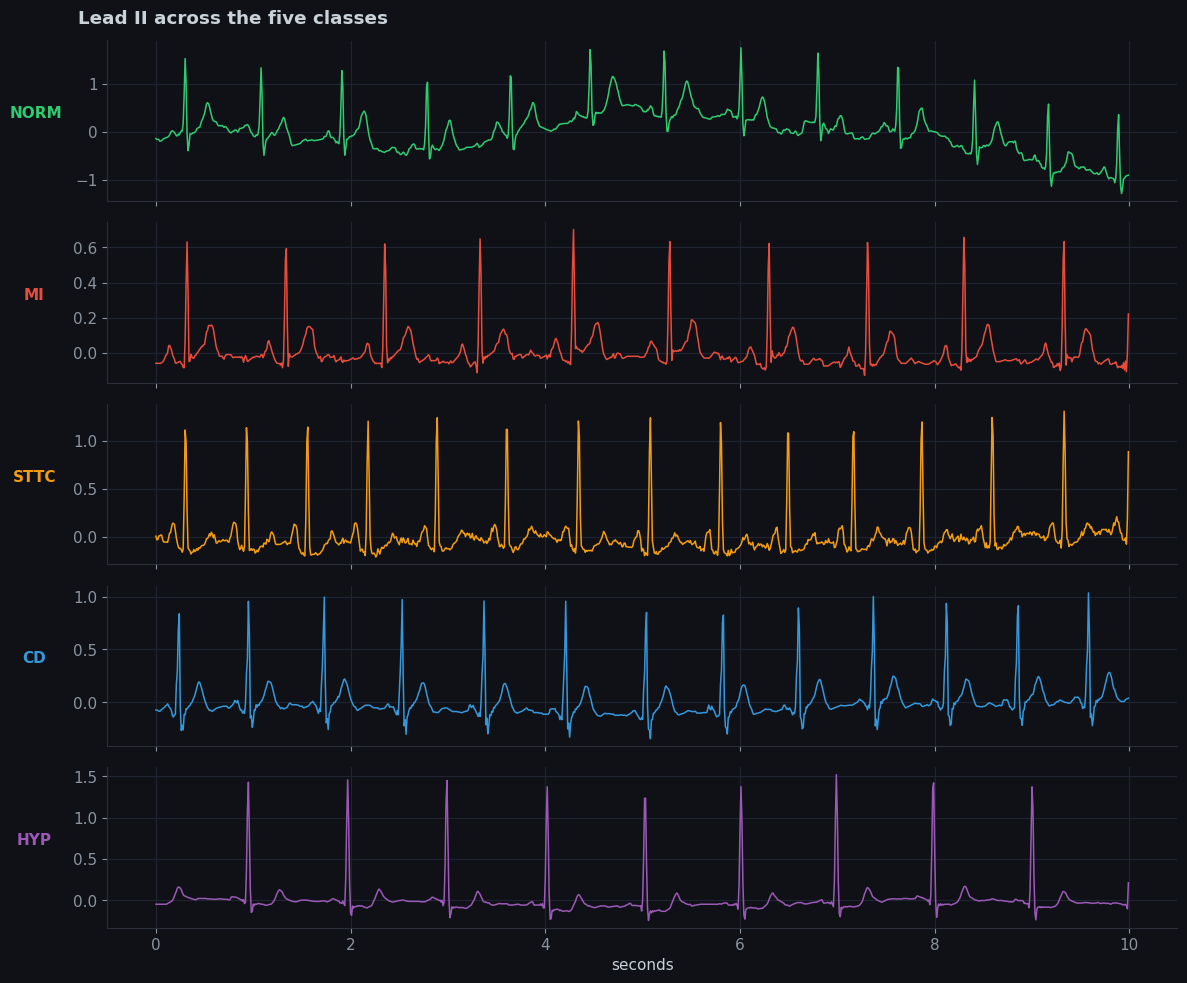

In [8]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 4  ·  Visual sanity check               ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 2 · Sanity check', 'One representative lead-II trace per condition')

fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
t = np.arange(X.shape[1]) / FS
for ax, c in zip(axes, CLASSES):
    k = CLASSES.index(c)
    idx = np.where((Y[:, k] == 1) & (Y.sum(1) == 1))[0][3]       # a clean single-label example
    ax.plot(t, X[idx, :, 1], color=COLORS[c], lw=1.1)
    ax.set_ylabel(c, rotation=0, labelpad=28, fontweight='bold', color=COLORS[c])
axes[-1].set_xlabel('seconds')
plt.suptitle('Lead II across the five classes', x=0.07, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

In [9]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 5  ·  Data → GPU                        ║
# ╚══════════════════════════════════════════════════════════╝
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score, f1_score, roc_curve

banner('Step 3 · Signal model', 'Preparing tensors for IsolineSignalNet (1D CNN + Transformer)')
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

X = np.load(f"{DIRS['data']}/X.npy").transpose(0, 2, 1)      # (N, 12 leads, 1000 samples)
Y = np.load(f"{DIRS['data']}/Y.npy")
meta = pd.read_csv(f"{DIRS['data']}/meta.csv", index_col='ecg_id')
tr, va, te = [(meta.split == s).values for s in ['train', 'val', 'test']]

# per-lead normalisation, statistics from TRAIN only (no leakage)
mu  = X[tr].mean(axis=(0, 2), keepdims=True)
std = X[tr].std(axis=(0, 2), keepdims=True) + 1e-6
np.savez(f"{DIRS['weights']}/signal_norm.npz", mu=mu, std=std)   # needed later for deployment
X = ((X - mu) / std).astype(np.float32)

T = lambda a: torch.tensor(a).to(device)
Xtr, Ytr, Xva, Yva, Xte, Yte = T(X[tr]), T(Y[tr]), T(X[va]), T(Y[va]), T(X[te]), T(Y[te])
print(f'train {tuple(Xtr.shape)} | val {tuple(Xva.shape)} | test {tuple(Xte.shape)} | device: {device}')

train (17084, 12, 1000) | val (2146, 12, 1000) | test (2158, 12, 1000) | device: cuda


In [10]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 6  ·  IsolineSignalNet                  ║
# ║  Residual 1D-CNN (local morphology) + Transformer (rhythm)║
# ╚══════════════════════════════════════════════════════════╝
import copy, math

class SE(nn.Module):                      # squeeze-and-excitation: learns which channels matter
    def __init__(s, c, r=8):
        super().__init__()
        s.f1, s.f2 = nn.Linear(c, c // r), nn.Linear(c // r, c)
    def forward(s, x):
        w = torch.sigmoid(s.f2(F.relu(s.f1(x.mean(-1)))))
        return x * w.unsqueeze(-1)

class ResBlock(nn.Module):
    def __init__(s, cin, cout, stride):
        super().__init__()
        s.c1, s.b1 = nn.Conv1d(cin, cout, 7, stride, 3, bias=False), nn.BatchNorm1d(cout)
        s.c2, s.b2 = nn.Conv1d(cout, cout, 7, 1, 3, bias=False), nn.BatchNorm1d(cout)
        s.se, s.drop = SE(cout), nn.Dropout(0.1)
        s.sc = (nn.Sequential(nn.Conv1d(cin, cout, 1, stride, bias=False), nn.BatchNorm1d(cout))
                if (stride != 1 or cin != cout) else nn.Identity())
    def forward(s, x):
        o = s.drop(F.relu(s.b1(s.c1(x))))
        o = s.se(s.b2(s.c2(o)))
        return F.relu(o + s.sc(x))

class IsolineSignalNet(nn.Module):
    def __init__(s, n_leads=12, n_cls=5, d=256, heads=4, layers=3, L=125):
        super().__init__()
        s.stem = nn.Sequential(nn.Conv1d(n_leads, 64, 15, 2, 7, bias=False),
                               nn.BatchNorm1d(64), nn.ReLU())
        cfg = [(64, 64, 1), (64, 128, 2), (128, 128, 1), (128, 256, 2), (256, 256, 1)]
        s.cnn = nn.Sequential(*[ResBlock(a, b, st) for a, b, st in cfg])   # 1000 -> 125 tokens
        s.pos = nn.Parameter(torch.zeros(1, L, d)); nn.init.trunc_normal_(s.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=512, dropout=0.1,
                                           batch_first=True, norm_first=True, activation='gelu')
        s.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        s.norm = nn.LayerNorm(d)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * d, n_cls))
    def forward(s, x):                                  # x: (B, 12, 1000)
        h = s.cnn(s.stem(x)).transpose(1, 2)            # (B, 125, 256)
        h = s.norm(s.tf(h + s.pos))
        return s.head(torch.cat([h.mean(1), h.amax(1)], 1))   # logits (B, 5)

class EMA:                                              # smoothed copy of the weights, usually generalises better
    def __init__(s, model, decay=0.998):
        s.m, s.d, s.n = copy.deepcopy(model).eval(), decay, 0
        for p in s.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(s, model):
        s.n += 1; d = min(s.d, (1 + s.n) / (10 + s.n))
        for e, p in zip(s.m.state_dict().values(), model.state_dict().values()):
            e.mul_(d).add_(p.detach(), alpha=1 - d) if e.dtype.is_floating_point else e.copy_(p)

banner('Step 3 · Model', 'IsolineSignalNet: residual CNN + squeeze-excite + 3-layer Transformer')
_m = IsolineSignalNet().to(device)
print('Output shape:', tuple(_m(torch.randn(2, 12, 1000, device=device)).shape))
print(f'Parameters  : {sum(p.numel() for p in _m.parameters())/1e6:.2f} M')
del _m

Output shape: (2, 5)
Parameters  : 3.78 M


In [11]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 7  ·  Training                          ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 3 · Training', '40 epochs · AdamW · one-cycle LR · mixed precision · EMA · best-on-val saved to Drive')

@torch.no_grad()
def predict(model, Xs, shifts=(0,), bs=512):
    model.eval(); out = []
    for i in range(0, len(Xs), bs):
        xb = Xs[i:i + bs]
        with torch.autocast('cuda', dtype=torch.float16, enabled=(device == 'cuda')):
            lg = torch.stack([model(torch.roll(xb, s, dims=2)).float() for s in shifts]).mean(0)
        out.append(lg.cpu())
    return torch.cat(out).numpy()

def augment(x):                                         # all on GPU, per-sample randomness
    B, C, L = x.shape; dv = x.device
    sh  = torch.randint(-60, 61, (B,), device=dv)       # random time shift
    idx = (torch.arange(L, device=dv)[None] - sh[:, None]) % L
    x   = x.gather(2, idx[:, None, :].expand(B, C, L))
    x   = x * torch.empty(B, C, 1, device=dv).uniform_(0.8, 1.2)          # amplitude change
    t   = torch.arange(L, device=dv)[None, None] / FS
    f, ph, amp = (torch.empty(B, 1, 1, device=dv).uniform_(a, b) for a, b in [(0.1, 0.5), (0, 6.283), (0, 0.3)])
    x   = x + amp * torch.sin(2 * math.pi * f * t + ph)                   # baseline wander
    x   = x + 0.03 * torch.randn_like(x)                                   # sensor noise
    return x * (torch.rand(B, C, 1, device=dv) > 0.04).float()            # randomly dropped leads

EPOCHS, BS, LR = 40, 128, 2e-3
model = IsolineSignalNet().to(device)
ema   = EMA(model)
opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * (len(Xtr) // BS), pct_start=0.15)
scaler = torch.amp.GradScaler('cuda')
Yva_np, Yte_np = Yva.cpu().numpy(), Yte.cpu().numpy()
CKPT = f"{DIRS['weights']}/isoline_signal_net.pt"

hist, best, t0 = {'loss': [], 'auc': []}, 0.0, time.time()
print(f"{'epoch':>5} {'loss':>8} {'val AUC':>9} {'best':>8} {'time':>7}")
for ep in range(1, EPOCHS + 1):
    model.train(); perm = torch.randperm(len(Xtr), device=device); run, n = 0., 0
    for i in range(0, len(perm) - BS + 1, BS):
        b = perm[i:i + BS]; xb, yb = augment(Xtr[b]), Ytr[b]
        with torch.autocast('cuda', dtype=torch.float16):
            loss = F.binary_cross_entropy_with_logits(model(xb).float(), yb)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step(); ema.update(model)
        run += loss.item(); n += 1
    auc = roc_auc_score(Yva_np, 1 / (1 + np.exp(-predict(ema.m, Xva))), average='macro')
    hist['loss'].append(run / n); hist['auc'].append(auc)
    if auc > best:
        best = auc; torch.save(ema.m.state_dict(), CKPT)
    print(f'{ep:>5} {run/n:>8.4f} {auc:>9.4f} {best:>8.4f} {time.time()-t0:>6.0f}s' + ('  ★' if auc == best else ''))
json.dump(hist, open(f"{DIRS['results']}/signal_history.json", 'w'))
print(f'\nDone. Best validation macro AUC = {best:.4f}  ->  saved {CKPT}')

epoch     loss   val AUC     best    time
    1   0.4019    0.8922   0.8922     12s  ★
    2   0.3235    0.9128   0.9128     22s  ★
    3   0.3052    0.9173   0.9173     33s  ★
    4   0.2976    0.9192   0.9192     44s  ★
    5   0.2901    0.9226   0.9226     55s  ★
    6   0.2836    0.9248   0.9248     66s  ★
    7   0.2753    0.9274   0.9274     77s  ★
    8   0.2693    0.9280   0.9280     89s  ★
    9   0.2606    0.9295   0.9295    101s  ★
   10   0.2564    0.9310   0.9310    112s  ★
   11   0.2525    0.9316   0.9316    123s  ★
   12   0.2493    0.9318   0.9318    135s  ★
   13   0.2458    0.9313   0.9318    146s
   14   0.2433    0.9316   0.9318    157s
   15   0.2366    0.9316   0.9318    168s
   16   0.2346    0.9317   0.9318    179s
   17   0.2308    0.9311   0.9318    191s
   18   0.2295    0.9309   0.9318    202s
   19   0.2230    0.9323   0.9323    213s  ★
   20   0.2224    0.9331   0.9331    225s  ★
   21   0.2173    0.9332   0.9332    236s  ★
   22   0.2143    0.9332   0.93

        AUC     F1  threshold
NORM  0.951  0.856       0.64
MI    0.931  0.770       0.33
STTC  0.938  0.752       0.29
CD    0.925  0.774       0.57
HYP   0.902  0.602       0.36


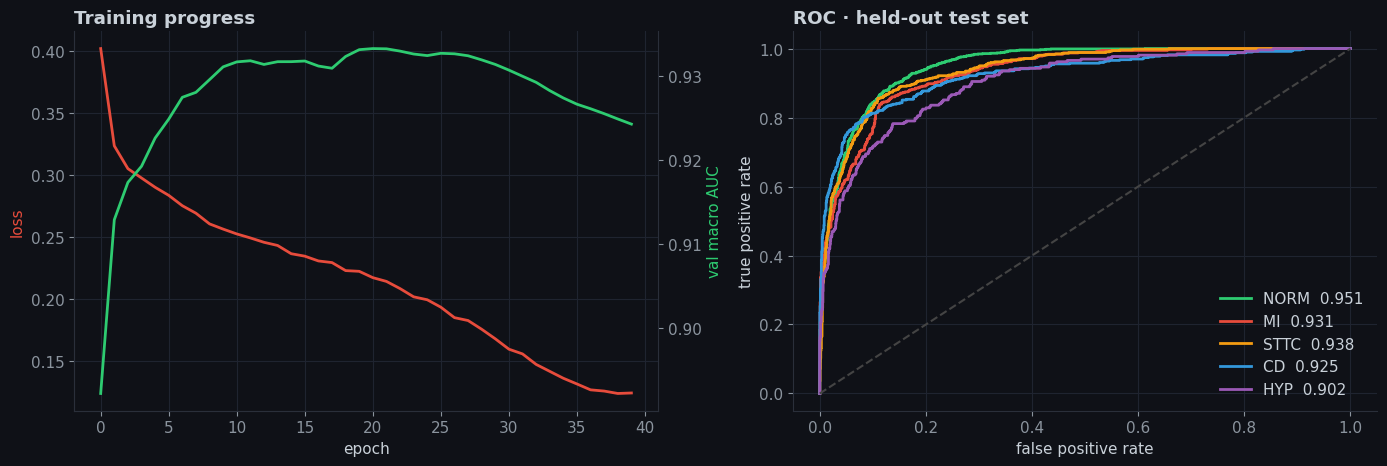

Saved: weights, metrics, calibration and plots in Drive/isoline


In [12]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 8  ·  Test evaluation + calibration     ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 3 · Evaluation', 'Held-out test set · test-time augmentation · calibrated probabilities · tuned thresholds')

best_m = IsolineSignalNet().to(device); best_m.load_state_dict(torch.load(CKPT)); best_m.eval()
SH = (-30, 0, 30)                                                   # test-time augmentation
lv, lt = predict(best_m, Xva, SH), predict(best_m, Xte, SH)
sig = lambda z: 1 / (1 + np.exp(-z))

# temperature scaling, fitted on VAL only
lvt, yv = torch.tensor(lv), torch.tensor(Yva_np)
logT = torch.zeros(1, requires_grad=True)
opt_T = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
def closure():
    opt_T.zero_grad(); l = F.binary_cross_entropy_with_logits(lvt / logT.exp(), yv); l.backward(); return l
nll_before = F.binary_cross_entropy_with_logits(lvt, yv).item()
opt_T.step(closure); TEMP = logT.exp().item()
nll_after = F.binary_cross_entropy_with_logits(lvt / TEMP, yv).item()

pva, pte = sig(lv / TEMP), sig(lt / TEMP)

# per-class thresholds, tuned on VAL only
ths = []
for k in range(len(CLASSES)):
    grid = np.arange(0.05, 0.95, 0.01)
    ths.append(float(grid[np.argmax([f1_score(Yva_np[:, k], pva[:, k] > g) for g in grid])]))
pred = (pte > np.array(ths)).astype(int)

aucs = [roc_auc_score(Yte_np[:, k], pte[:, k]) for k in range(5)]
f1s  = [f1_score(Yte_np[:, k], pred[:, k]) for k in range(5)]
macro_auc, macro_f1 = float(np.mean(aucs)), float(np.mean(f1s))

display(HTML(f"""
<div style="display:flex;gap:14px;font-family:sans-serif;margin:8px 0">
  <div style="flex:1;background:#161b26;border-top:4px solid #2ecc71;padding:16px;border-radius:8px">
    <div style="color:#8b949e;font-size:12px;letter-spacing:2px">TEST MACRO AUC</div>
    <div style="color:#2ecc71;font-size:36px;font-weight:700">{macro_auc:.3f}</div></div>
  <div style="flex:1;background:#161b26;border-top:4px solid #3498db;padding:16px;border-radius:8px">
    <div style="color:#8b949e;font-size:12px;letter-spacing:2px">TEST MACRO F1</div>
    <div style="color:#3498db;font-size:36px;font-weight:700">{macro_f1:.3f}</div></div>
  <div style="flex:1;background:#161b26;border-top:4px solid #f39c12;padding:16px;border-radius:8px">
    <div style="color:#8b949e;font-size:12px;letter-spacing:2px">CALIBRATION (BCE)</div>
    <div style="color:#f39c12;font-size:36px;font-weight:700">{nll_before:.3f} → {nll_after:.3f}</div></div>
</div>"""))
print(pd.DataFrame({'AUC': aucs, 'F1': f1s, 'threshold': ths}, index=CLASSES).round(3).to_string())

# plots
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(hist['loss'], color='#e74c3c', lw=2, label='train loss')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss', color='#e74c3c')
a2 = ax[0].twinx(); a2.plot(hist['auc'], color='#2ecc71', lw=2); a2.set_ylabel('val macro AUC', color='#2ecc71')
a2.grid(False); a2.spines['right'].set_visible(True)
ax[0].set_title('Training progress', loc='left', fontweight='bold')
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Yte_np[:, k], pte[:, k])
    ax[1].plot(fpr, tpr, color=COLORS[c], lw=2, label=f'{c}  {aucs[k]:.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='#444')
ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate')
ax[1].set_title('ROC · held-out test set', loc='left', fontweight='bold'); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/signal_results.png", dpi=160); plt.show()

json.dump({'macro_auc': macro_auc, 'macro_f1': macro_f1, 'per_class_auc': dict(zip(CLASSES, aucs)),
           'per_class_f1': dict(zip(CLASSES, f1s)), 'temperature': TEMP,
           'thresholds': dict(zip(CLASSES, ths))},
          open(f"{DIRS['results']}/signal_metrics.json", 'w'), indent=2)
print('Saved: weights, metrics, calibration and plots in Drive/isoline')

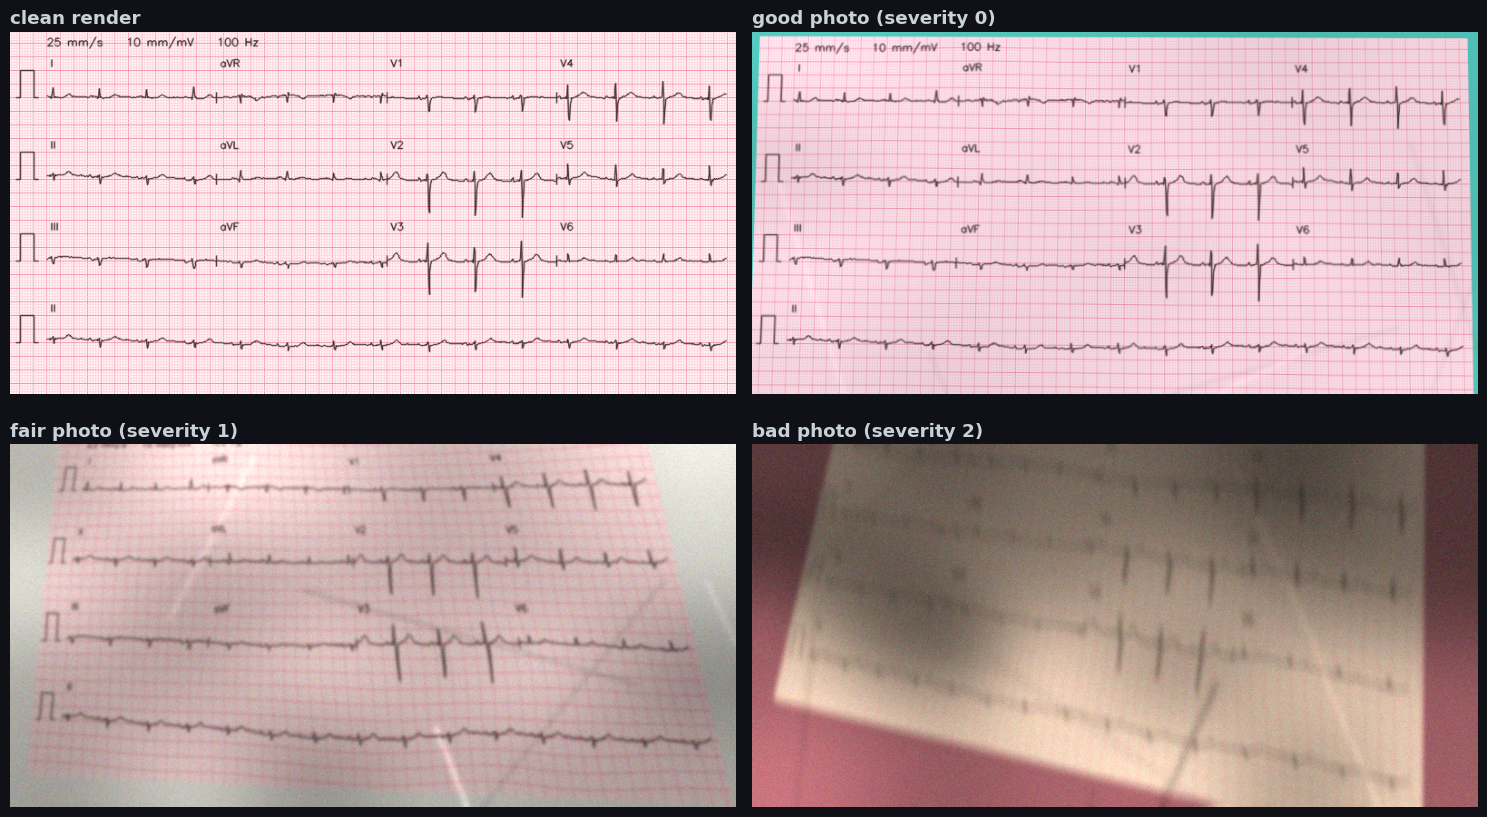

In [13]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 9  ·  ECG paper renderer + camera lab   ║
# ╚══════════════════════════════════════════════════════════╝
import cv2
cv2.setNumThreads(0)                      # single-threaded OpenCV: safe with multiprocessing later

banner('Step 4 · Image studio', 'Printing clinical 12-lead ECG paper, then photographing it badly on purpose')

# ---------- page geometry: 25 mm/s · 10 mm/mV · 3 px per mm ----------
PX, W, H, X0, Y0 = 3, 800, 400, 40, 28
ROW_H, MV, PXS = 30 * PX, 10 * PX, 25 * PX / FS          # row height · px per mV · px per sample
LAYOUT = [[0, 3, 6, 9], [1, 4, 7, 10], [2, 5, 8, 11]]    # standard 3x4 grid (I/II/III · aVR/aVL/aVF · V1-3 · V4-6)
NAMES  = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
FONT   = cv2.FONT_HERSHEY_SIMPLEX

# ---------- three kinds of ECG paper (BGR): paper, minor grid, major grid ----------
PAPERS = {}
for name, (paper, minor, major) in {'pink': ((250, 247, 255), (222, 214, 255), (170, 150, 245)),
                                    'red' : ((245, 245, 252), (200, 200, 250), (120, 120, 230)),
                                    'grey': ((250, 250, 250), (228, 228, 228), (185, 185, 185))}.items():
    pg = np.empty((H, W, 3), np.uint8); pg[:] = paper
    for x in range(X0 % PX, W, PX):
        pg[:, x] = major if ((x - X0) // PX) % 5 == 0 else minor
    for y in range(Y0 % PX, H, PX):
        pg[y, :] = major if ((y - Y0) // PX) % 5 == 0 else minor
    PAPERS[name] = pg
INKS = [(25, 25, 25), (60, 30, 20), (40, 40, 60)]


def render_ecg(sig, rng, paper=None, thick=None):
    """sig: (1000, 12) in mV  ->  800x400 BGR picture of a standard 12-lead printout."""
    paper = paper if paper is not None else str(rng.choice(list(PAPERS), p=[.6, .2, .2]))
    thick = thick if thick is not None else int(rng.choice([1, 2], p=[.6, .4]))
    ink   = INKS[int(rng.integers(len(INKS)))]
    img   = PAPERS[paper].copy()
    sig   = np.clip(sig - np.median(sig, 0), -2.5, 2.5)          # centre baseline, tame huge spikes

    def trace(seg, x_start, yc):
        xs  = x_start + np.arange(len(seg)) * PXS
        pts = np.stack([xs, yc - seg * MV], 1).round().astype(np.int32)
        cv2.polylines(img, [pts], False, ink, thick, cv2.LINE_AA)

    for r in range(3):                                            # 3 rows x 4 columns of 2.5 s
        yc = int(Y0 + (r + .5) * ROW_H)
        for c in range(4):
            li, xs = LAYOUT[r][c], X0 + c * 250 * PXS
            trace(sig[c * 250:(c + 1) * 250, li], xs, yc)
            cv2.putText(img, NAMES[li], (int(xs) + 4, int(yc - ROW_H / 2 + 11)), FONT, .38, ink, 1, cv2.LINE_AA)
            if c: cv2.line(img, (int(xs), yc - 6), (int(xs), yc + 6), ink, 1, cv2.LINE_AA)
    yc = int(Y0 + 3.5 * ROW_H)                                    # 10-second rhythm strip, lead II
    trace(sig[:, 1], X0, yc)
    cv2.putText(img, 'II', (X0 + 4, int(yc - ROW_H / 2 + 11)), FONT, .38, ink, 1, cv2.LINE_AA)
    for r in range(4):                                            # 1 mV calibration pulse on every row
        yc = int(Y0 + (r + .5) * ROW_H)
        cal = np.array([[6, yc], [11, yc], [11, yc - MV], [26, yc - MV], [26, yc], [31, yc]], np.int32)
        cv2.polylines(img, [cal], False, ink, thick, cv2.LINE_AA)
    cv2.putText(img, '25 mm/s    10 mm/mV    100 Hz', (X0, 16), FONT, .4, ink, 1, cv2.LINE_AA)
    return img


# ---------- the camera lab: three levels of "real-world" abuse ----------
LEVELS = {
    0: dict(name='good', rot=1.0,  persp=.008, blur=(0., .6),  shadow=(0., .12),  wrinkle=(0., .04),   noise=(0, 3),  jpeg=(85, 96), shift=.01, bright=(.92, 1.08)),
    1: dict(name='fair', rot=4.0,  persp=.03,  blur=(.9, 1.6), shadow=(.15, .4),  wrinkle=(.06, .16),  noise=(3, 8),  jpeg=(55, 80), shift=.04, bright=(.78, 1.18)),
    2: dict(name='bad',  rot=11.0, persp=.07,  blur=(2., 3.6), shadow=(.4, .7),   wrinkle=(.16, .32),  noise=(8, 18), jpeg=(25, 50), shift=.10, bright=(.55, 1.3)),
}

def smooth_field(rng, h, w, gh=4, gw=6):
    return cv2.resize(rng.normal(size=(gh, gw)).astype(np.float32), (w, h), interpolation=cv2.INTER_CUBIC)

def degrade(img, sev, rng):
    """Turn a clean render into a 'phone photo'. Returns (uint8 image, parameter dict)."""
    L, p = LEVELS[sev], {}
    f = img.astype(np.float32)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)

    # 1 · crumpled paper: smooth geometric ripples
    wr = p['wrinkle'] = rng.uniform(*L['wrinkle'])
    if wr > .03:
        amp = wr * 14
        f = cv2.remap(f, xx + amp * smooth_field(rng, H, W, 5, 8), yy + amp * smooth_field(rng, H, W, 5, 8),
                      cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

    # 2 · camera pose: rotation + perspective + shift, page lying on a table
    ang = p['rot'] = rng.uniform(-L['rot'], L['rot'])
    sc  = rng.uniform(.9, .98) if sev else rng.uniform(.96, 1.0)
    c, a = np.array([W / 2, H / 2]), np.deg2rad(ang)
    R   = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    src = np.array([[0, 0], [W, 0], [W, H], [0, H]], np.float32)
    dst = (src - c) @ R.T * sc + c
    dst = dst + rng.normal(0, L['persp'], (4, 2)) * np.array([W, H])
    dst = dst + rng.uniform(-L['shift'], L['shift'], 2) * np.array([W, H])
    bg  = rng.integers(30, 235, 3) if rng.random() < .6 else np.full(3, rng.integers(215, 255))
    M   = cv2.getPerspectiveTransform(src, dst.astype(np.float32))
    f   = cv2.warpPerspective(f, M, (W, H), borderMode=cv2.BORDER_CONSTANT, borderValue=tuple(float(v) for v in bg))

    # 3 · lighting: soft shadow, optional hand/phone blob, creases, uneven exposure
    s = p['shadow'] = rng.uniform(*L['shadow'])
    th = rng.uniform(0, 2 * np.pi)
    g = np.cos(th) * (xx - W / 2) / W + np.sin(th) * (yy - H / 2) / H
    g = 1 / (1 + np.exp(-g * rng.uniform(4, 14) - rng.uniform(-1, 1)))
    shade = 1 - s * g
    if rng.random() < .5:
        blob = np.zeros((H, W), np.float32)
        cv2.ellipse(blob, (int(rng.uniform(0, W)), int(rng.uniform(0, H))),
                    (int(rng.uniform(60, 250)), int(rng.uniform(40, 150))), float(rng.uniform(0, 180)), 0, 360, 1.0, -1)
        shade = shade * (1 - s * .8 * cv2.GaussianBlur(blob, (0, 0), 35))
    wl = np.zeros((H, W), np.float32)
    for _ in range(int(rng.integers(3, 9)) if wr > .03 else 0):
        p1 = rng.uniform((0, 0), (W, H)); a2 = rng.uniform(0, np.pi); ln = rng.uniform(150, 700)
        p2 = p1 + ln * np.array([np.cos(a2), np.sin(a2)])
        cv2.line(wl, tuple(int(v) for v in p1), tuple(int(v) for v in p2), float(rng.choice([-1, 1])), int(rng.integers(1, 3)))
    wl = cv2.GaussianBlur(wl, (0, 0), 2.5); wl = wl / (np.abs(wl).max() + 1e-6)
    shade = shade * (1 + wr * 1.6 * wl + wr * .6 * smooth_field(rng, H, W, 4, 6))
    f = f * np.clip(shade, .08, 1.4)[..., None]

    # 4 · focus: lens blur and (sometimes) hand-shake
    sg = p['blur'] = rng.uniform(*L['blur'])
    if sg > .05: f = cv2.GaussianBlur(f, (0, 0), sg)
    p['motion'] = 0
    if sev and rng.random() < .35:
        k = p['motion'] = int(rng.integers(5, 9 + 4 * sev)) | 1
        ker = np.zeros((k, k), np.float32); ker[k // 2] = 1
        ker = cv2.warpAffine(ker, cv2.getRotationMatrix2D(((k - 1) / 2, (k - 1) / 2), float(rng.uniform(0, 180)), 1.), (k, k))
        f = cv2.filter2D(f, -1, ker / ker.sum())

    # 5 · sensor: noise, exposure, contrast, colour cast
    ns = p['noise'] = rng.uniform(*L['noise'])
    f = f + rng.standard_normal(f.shape, dtype=np.float32) * ns
    ct = rng.uniform(.8, 1.15) if sev else rng.uniform(.95, 1.05)
    f = ((f - 128) * ct + 128) * rng.uniform(*L['bright']) * (1 + rng.normal(0, .02 + .03 * sev, 3))
    p['jpeg'] = int(rng.integers(*L['jpeg']))
    return np.clip(f, 0, 255).astype(np.uint8), p


# ---------- preview: same ECG, four versions ----------
X_RAW = np.load(f"{DIRS['data']}/X.npy", mmap_mode='r')
Y_ALL = np.load(f"{DIRS['data']}/Y.npy")
k = int(np.where((Y_ALL[:, 1] == 1) & (Y_ALL.sum(1) == 1))[0][5])                 # a clean single-label MI example
base = render_ecg(np.asarray(X_RAW[k], np.float32), np.random.default_rng(7), paper='pink', thick=1)
panels = [('clean render', base)] + [(f'{LEVELS[s]["name"]} photo (severity {s})', degrade(base, s, np.random.default_rng(100 + s))[0]) for s in range(3)]
fig, axes = plt.subplots(2, 2, figsize=(15, 8.6))
for ax, (t, im) in zip(axes.ravel(), panels):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(t, loc='left', fontweight='bold'); ax.axis('off')
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/image_studio_preview.png", dpi=150); plt.show()

In [14]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 10  ·  Render the whole image dataset   ║
# ╚══════════════════════════════════════════════════════════╝
from multiprocessing import Pool
import pandas as pd
from tqdm.auto import tqdm

banner('Step 4 · Rendering', 'One clean printout + one phone-photo per ECG, saved as JPEG with a full manifest')

IMG_DIR = '/content/isoline_imgs'                                          # local disk = fast
os.makedirs(IMG_DIR, exist_ok=True)
SEV_P = [0.40, 0.35, 0.25]                                                # share of good / fair / bad photos
META  = pd.read_csv(f"{DIRS['data']}/meta.csv", index_col='ecg_id')
N_REC = len(META)

def render_one(i):
    rng = np.random.default_rng(SEED * 100003 + i)                        # reproducible per record
    sig = np.asarray(X_RAW[i], np.float32)
    clean = render_ecg(sig, rng)
    sev   = int(rng.choice(3, p=SEV_P))
    photo, p = degrade(clean, sev, rng)
    rows = []
    for kind, im, s, q in [('clean', clean, 0, 95), ('photo', photo, sev, p['jpeg'])]:
        fn = f'{i:05d}_{kind}.jpg'
        cv2.imwrite(f'{IMG_DIR}/{fn}', im, [cv2.IMWRITE_JPEG_QUALITY, int(q)])
        row = dict(idx=i, kind=kind, sev=s, quality=['good', 'fair', 'bad'][s], file=fn)
        if kind == 'photo': row.update({k: round(float(v), 4) for k, v in p.items()})
        rows.append(row)
    return rows

t0 = time.time()
with Pool(max(1, os.cpu_count())) as pool:
    out = list(tqdm(pool.imap(render_one, range(N_REC), chunksize=32), total=N_REC, desc='Rendering'))
man = pd.DataFrame([r for rows in out for r in rows])
man['split'] = META.split.values[man.idx.values]
man.to_csv(f"{DIRS['data']}/image_manifest.csv", index=False)
print(f'{len(man):,} images in {time.time()-t0:.0f}s  ->  {IMG_DIR}')
print(man.groupby(['kind', 'quality']).size().unstack(fill_value=0).to_string())

Rendering:   0%|          | 0/21388 [00:00<?, ?it/s]

42,776 images in 1623s  ->  /content/isoline_imgs
quality   bad  fair   good
kind                      
clean       0     0  21388
photo    5369  7379   8640


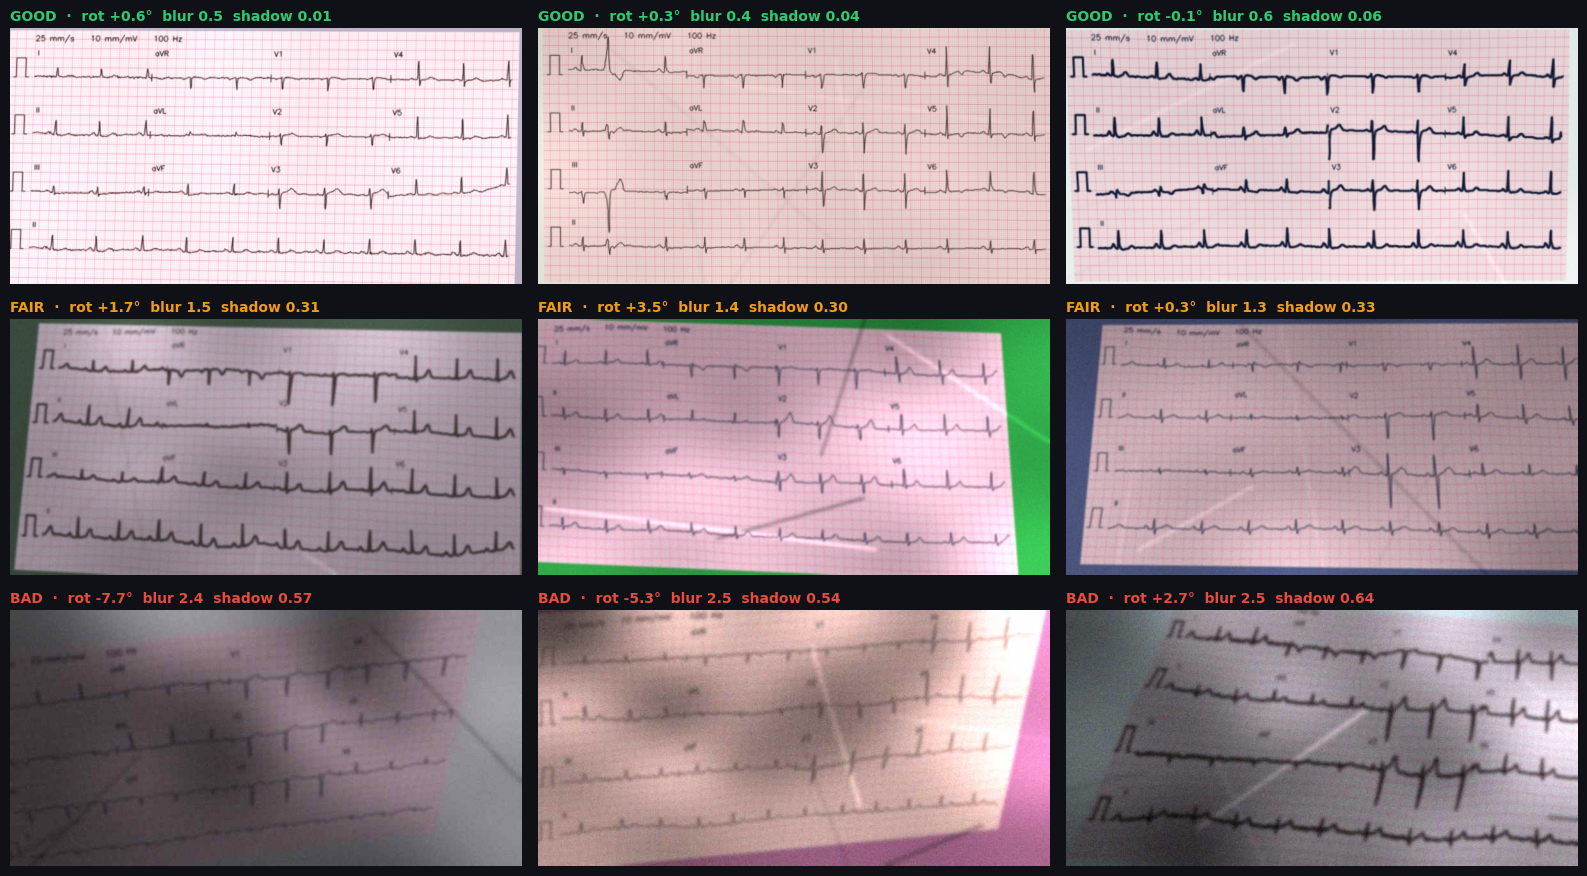

quality   bad  fair   good
split                     
test      575   716   3025
train    4277  5918  23973
val       517   745   3030


In [15]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 11  ·  Gallery: does the data look right?║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 4 · Gallery', 'Random photos from each quality level, straight from the saved dataset')
man = pd.read_csv(f"{DIRS['data']}/image_manifest.csv")
ph  = man[man.kind == 'photo']
rg  = np.random.default_rng(3)
fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for r, q in enumerate(['good', 'fair', 'bad']):
    for c, row in enumerate(ph[ph.quality == q].sample(3, random_state=int(rg.integers(1000))).itertuples()):
        im = cv2.cvtColor(cv2.imread(f'{IMG_DIR}/{row.file}'), cv2.COLOR_BGR2RGB)
        axes[r, c].imshow(im); axes[r, c].axis('off')
        axes[r, c].set_title(f'{q.upper()}  ·  rot {row.rot:+.1f}°  blur {row.blur:.1f}  shadow {row.shadow:.2f}',
                             loc='left', fontsize=10, color={'good': '#2ecc71', 'fair': '#f39c12', 'bad': '#e74c3c'}[q], fontweight='bold')
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/image_gallery.png", dpi=140); plt.show()
print(man.groupby(['split', 'quality']).size().unstack(fill_value=0).to_string())

Decoding:   0%|          | 0/42776 [00:00<?, ?it/s]

Array (42776, 192, 384, 3)  9.5 GB  in 258s  ->  /content/isoline_arr.npy
Row alignment check passed.  Mean pixel value: 201.6


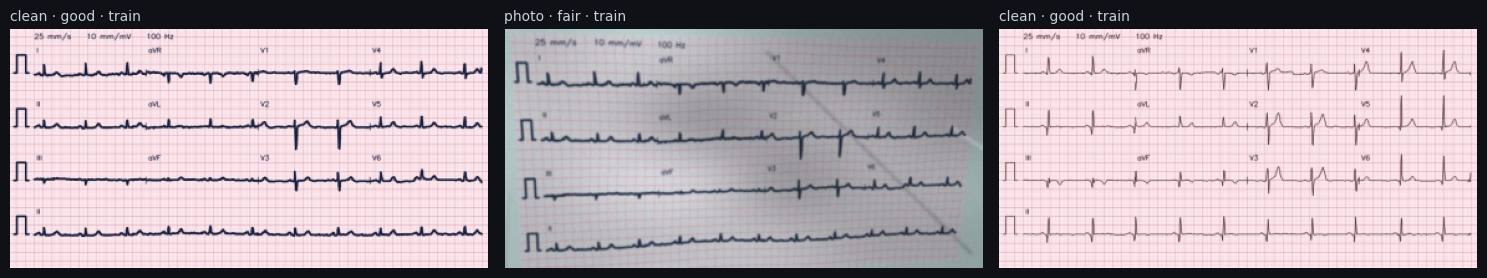

In [16]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 12  ·  Images → one fast array          ║
# ╚══════════════════════════════════════════════════════════╝
from multiprocessing import Pool
from tqdm.auto import tqdm

banner('Step 5 · Data prep', 'Decoding every JPEG once into a 384x192 array so training runs at full GPU speed')

IMG_DIR  = '/content/isoline_imgs'
ARR_PATH = '/content/isoline_arr.npy'
IW, IH   = 384, 192

man = pd.read_csv(f"{DIRS['data']}/image_manifest.csv")
assert len(man) > 0, 'manifest is empty: run Cell 10 first'

def load_small(fn):
    im = cv2.imread(f'{IMG_DIR}/{fn}')
    assert im is not None, f'cannot read {fn}'
    return cv2.cvtColor(cv2.resize(im, (IW, IH), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

arr = np.lib.format.open_memmap(ARR_PATH, mode='w+', dtype=np.uint8, shape=(len(man), IH, IW, 3))
t0 = time.time()
with Pool(max(1, os.cpu_count())) as pool:
    for i, im in enumerate(tqdm(pool.imap(load_small, man.file.tolist(), chunksize=64), total=len(man), desc='Decoding')):
        arr[i] = im
arr.flush()
print(f'Array {arr.shape}  {arr.nbytes/1e9:.1f} GB  in {time.time()-t0:.0f}s  ->  {ARR_PATH}')

# sanity: the array must match the manifest row-for-row
for j in np.random.default_rng(0).choice(len(man), 3, replace=False):
    ref = load_small(man.file[j])
    assert np.array_equal(arr[j], ref), f'row {j} mismatch'
print('Row alignment check passed.  Mean pixel value:', round(float(arr[:200].mean()), 1))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for a, j in zip(ax, [0, 1, len(man) // 2]):
    a.imshow(arr[j]); a.axis('off')
    a.set_title(f'{man.kind[j]} · {man.quality[j]} · {man.split[j]}', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

In [17]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 13  ·  IsolineImageNet                  ║
# ║  EfficientNet-B0 · diagnosis head + photo-quality head    ║
# ╚══════════════════════════════════════════════════════════╝
import threading, queue, copy
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from sklearn.metrics import roc_auc_score, f1_score, roc_curve, confusion_matrix

banner('Step 5 · Image model', 'EfficientNet-B0 · 5 diagnoses + photo quality · mixed precision · EMA · best-on-val saved to Drive')
torch.manual_seed(SEED); np.random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
assert device == 'cuda', 'No GPU: use Runtime > Change runtime type > T4 GPU, then re-run Cells 1, 9, 12 and this one'

man = pd.read_csv(f"{DIRS['data']}/image_manifest.csv")
arr = np.load('/content/isoline_arr.npy', mmap_mode='r')
assert len(arr) == len(man), 'array and manifest are out of sync: re-run Cell 12'
IH, IW = arr.shape[1:3]
LAB_D = np.load(f"{DIRS['data']}/Y.npy")[man.idx.values].astype(np.float32)    # (rows, 5) diagnoses
LAB_Q = man.sev.values.astype(np.int64)                                        # (rows,) 0 good · 1 fair · 2 bad
KIND  = man.kind.values
ROWS  = {s: np.where(man.split.values == s)[0] for s in ['train', 'val', 'test']}
print({k: len(v) for k, v in ROWS.items()}, '| device:', device, '| image size:', (IH, IW))

# ---------------- fast batch feeder (background thread reads the memmap while the GPU trains) ----------------
def batches(rows, bs, shuffle=False, drop_last=False):
    rows  = np.asarray(rows)
    order = np.random.permutation(len(rows)) if shuffle else np.arange(len(rows))
    q = queue.Queue(maxsize=6)
    def work():
        try:
            for i in range(0, len(order), bs):
                sel = order[i:i + bs]
                if drop_last and len(sel) < bs: break
                ridx = rows[sel]; srt = np.argsort(ridx)
                x = np.empty((len(sel), IH, IW, 3), np.uint8)
                x[srt] = arr[ridx[srt]]                      # sorted read is much faster on a memmap
                q.put((torch.from_numpy(x), ridx))
            q.put(None)
        except Exception as e:
            q.put(e)
    threading.Thread(target=work, daemon=True).start()
    while True:
        item = q.get()
        if item is None: return
        if isinstance(item, Exception): raise item
        yield item

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
to_gpu = lambda xb: xb.to(device, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
norm   = lambda x: ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def aug_img(x):                                              # light, GPU-side: brightness · contrast · noise · small shift
    B = x.size(0)
    c = torch.empty(B, 1, 1, 1, device=x.device).uniform_(0.85, 1.15)
    b = torch.empty(B, 1, 1, 1, device=x.device).uniform_(0.85, 1.15)
    m = x.mean((1, 2, 3), keepdim=True)
    x = ((x - m) * c + m) * b + 0.02 * torch.randn_like(x)
    x = torch.roll(x, shifts=(int(np.random.randint(-6, 7)), int(np.random.randint(-12, 13))), dims=(2, 3))
    return x.clamp(0, 1)

# ---------------- model ----------------
class IsolineImageNet(nn.Module):
    def __init__(s, pretrained=True):
        super().__init__()
        try:
            w = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
            m = torchvision.models.efficientnet_b0(weights=w)
        except Exception as e:
            print('WARNING: could not load pretrained weights, training from scratch ->', e)
            m = torchvision.models.efficientnet_b0(weights=None)
        s.features, s.pool, s.drop = m.features, nn.AdaptiveAvgPool2d(1), nn.Dropout(0.3)
        s.diag, s.qual = nn.Linear(1280, 5), nn.Linear(1280, 3)
    def forward(s, x):
        h = s.drop(s.pool(s.features(x)).flatten(1))
        return s.diag(h), s.qual(h)

class ImgEMA:
    def __init__(s, model, decay=0.998):
        s.m, s.d, s.n = copy.deepcopy(model).eval(), decay, 0
        for p in s.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(s, model):
        s.n += 1; d = min(s.d, (1 + s.n) / (10 + s.n))
        for e, p in zip(s.m.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(p.detach(), alpha=1 - d)
            else: e.copy_(p)

@torch.no_grad()
def predict_img(model, rows, bs=256):
    model.eval(); LD, LQ = [], []
    for xb, _ in batches(rows, bs):
        with torch.autocast('cuda', dtype=torch.float16):
            ld, lq = model(norm(to_gpu(xb)))
        LD.append(ld.float().cpu()); LQ.append(lq.float().cpu())
    return torch.cat(LD).numpy(), torch.cat(LQ).numpy()

sigm = lambda z: 1 / (1 + np.exp(-z))

# ---------------- training ----------------
EPOCHS, BS, LR = 10, 64, 1e-3
imodel = IsolineImageNet().to(device).to(memory_format=torch.channels_last)
iema   = ImgEMA(imodel)
opt    = torch.optim.AdamW(imodel.parameters(), lr=LR, weight_decay=1e-2)
spe    = len(ROWS['train']) // BS
sched  = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * spe, pct_start=0.2)
scaler = torch.amp.GradScaler('cuda')
ICKPT  = f"{DIRS['weights']}/isoline_image_net.pt"
Yv, Qv = LAB_D[ROWS['val']], LAB_Q[ROWS['val']]

print(f"Parameters: {sum(p.numel() for p in imodel.parameters())/1e6:.2f} M | steps/epoch: {spe}")
print(f"{'epoch':>5} {'loss':>8} {'val AUC':>9} {'qual acc':>9} {'score':>7} {'time':>7}")
ihist, ibest, t0 = {'loss': [], 'auc': [], 'qacc': []}, -1.0, time.time()
for ep in range(1, EPOCHS + 1):
    imodel.train(); run, n = 0., 0
    for xb, ridx in batches(ROWS['train'], BS, shuffle=True, drop_last=True):
        x  = norm(aug_img(to_gpu(xb)))
        yd = torch.from_numpy(LAB_D[ridx]).to(device); yq = torch.from_numpy(LAB_Q[ridx]).to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            ld, lq = imodel(x)
        loss = F.binary_cross_entropy_with_logits(ld.float(), yd) + 0.5 * F.cross_entropy(lq.float(), yq)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(imodel.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step(); iema.update(imodel)
        run += loss.item(); n += 1
    lv_d, lv_q = predict_img(iema.m, ROWS['val'])
    auc, qacc = roc_auc_score(Yv, sigm(lv_d), average='macro'), float((lv_q.argmax(1) == Qv).mean())
    score = auc + 0.25 * qacc
    ihist['loss'].append(run / n); ihist['auc'].append(auc); ihist['qacc'].append(qacc)
    star = score > ibest
    if star: ibest = score; torch.save(iema.m.state_dict(), ICKPT)
    print(f'{ep:>5} {run/n:>8.4f} {auc:>9.4f} {qacc:>9.4f} {score:>7.4f} {time.time()-t0:>6.0f}s' + ('  ★' if star else ''))
json.dump(ihist, open(f"{DIRS['results']}/image_history.json", 'w'))
print(f'\nDone. Best checkpoint saved -> {ICKPT}')

{'train': 34168, 'val': 4292, 'test': 4316} | device: cuda | image size: (192, 384)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s]


Parameters: 4.02 M | steps/epoch: 533
epoch     loss   val AUC  qual acc   score    time
    1   0.5118    0.8746    0.9718  1.1176    139s  ★
    2   0.3335    0.9127    0.9858  1.1592    271s  ★
    3   0.2963    0.9201    0.9877  1.1670    404s  ★
    4   0.2757    0.9237    0.9872  1.1705    537s  ★
    5   0.2601    0.9254    0.9858  1.1718    669s  ★
    6   0.2443    0.9262    0.9872  1.1730    802s  ★
    7   0.2236    0.9258    0.9902  1.1733    934s  ★
    8   0.1993    0.9238    0.9916  1.1717   1066s
    9   0.1726    0.9211    0.9904  1.1688   1198s
   10   0.1577    0.9186    0.9907  1.1663   1332s

Done. Best checkpoint saved -> /content/drive/MyDrive/isoline/weights/isoline_image_net.pt


        AUC     F1  threshold
NORM  0.943  0.859       0.56
MI    0.914  0.727       0.42
STTC  0.934  0.764       0.39
CD    0.910  0.744       0.43
HYP   0.905  0.604       0.35

AUC on photos by quality  -> {'good': 0.924, 'fair': 0.925, 'bad': 0.877}
Calibration (BCE) val      -> 0.292 → 0.277

Quality-gate confusion (rows = truth, cols = predicted):
      good  fair  bad
good  3025     0    0
fair     0   716    0
bad      0    40  535


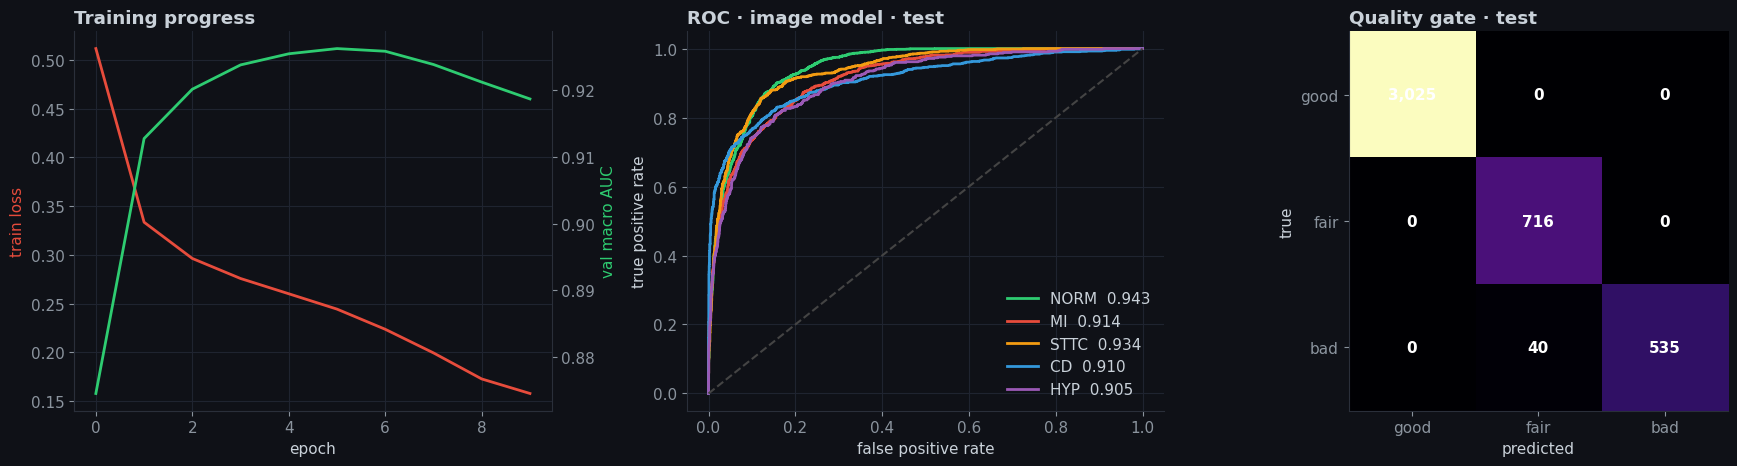


Saved: weights, metrics, test outputs and plots in Drive/isoline


In [18]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 14  ·  Image model: test evaluation     ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 5 · Evaluation', 'Held-out test set · calibrated probabilities · tuned thresholds · quality-gate accuracy')

best_img = IsolineImageNet(pretrained=False).to(device).to(memory_format=torch.channels_last)
best_img.load_state_dict(torch.load(ICKPT, map_location=device)); best_img.eval()
lv_d, lv_q = predict_img(best_img, ROWS['val'])
lt_d, lt_q = predict_img(best_img, ROWS['test'])
Yt, Qt, Kt = LAB_D[ROWS['test']], LAB_Q[ROWS['test']], KIND[ROWS['test']]

# temperature scaling for the diagnosis head, fitted on VAL only
lvt, yvt = torch.tensor(lv_d), torch.tensor(Yv)
logT = torch.zeros(1, requires_grad=True)
opt_T = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
def closure():
    opt_T.zero_grad(); l = F.binary_cross_entropy_with_logits(lvt / logT.exp(), yvt); l.backward(); return l
nll_b = F.binary_cross_entropy_with_logits(lvt, yvt).item()
opt_T.step(closure); ITEMP = logT.exp().item()
nll_a = F.binary_cross_entropy_with_logits(lvt / ITEMP, yvt).item()
pv_img, pt_img = sigm(lv_d / ITEMP), sigm(lt_d / ITEMP)

ithr = []                                                      # per-class thresholds, tuned on VAL only
for k in range(5):
    grid = np.arange(0.05, 0.95, 0.01)
    ithr.append(float(grid[np.argmax([f1_score(Yv[:, k], pv_img[:, k] > g) for g in grid])]))
pred = (pt_img > np.array(ithr)).astype(int)

i_aucs = [roc_auc_score(Yt[:, k], pt_img[:, k]) for k in range(5)]
i_f1s  = [f1_score(Yt[:, k], pred[:, k]) for k in range(5)]
auc_all = float(np.mean(i_aucs)); f1_all = float(np.mean(i_f1s))
ph, cl = Kt == 'photo', Kt == 'clean'
auc_ph = float(roc_auc_score(Yt[ph], pt_img[ph], average='macro'))
auc_cl = float(roc_auc_score(Yt[cl], pt_img[cl], average='macro'))
by_q = {q: float(roc_auc_score(Yt[ph & (Qt == s)], pt_img[ph & (Qt == s)], average='macro')) for s, q in enumerate(['good', 'fair', 'bad'])}
qpred = lt_q.argmax(1); qacc = float((qpred == Qt).mean())
cm = confusion_matrix(Qt, qpred, labels=[0, 1, 2])

card = lambda t, v, c: (f'<div style="flex:1;background:#161b26;border-top:4px solid {c};padding:16px;border-radius:8px">'
                        f'<div style="color:#8b949e;font-size:12px;letter-spacing:2px">{t}</div>'
                        f'<div style="color:{c};font-size:34px;font-weight:700">{v}</div></div>')
display(HTML('<div style="display:flex;gap:14px;font-family:sans-serif;margin:8px 0">'
             + card('TEST MACRO AUC · ALL', f'{auc_all:.3f}', '#2ecc71') + card('AUC · PHONE PHOTOS', f'{auc_ph:.3f}', '#3498db')
             + card('AUC · CLEAN PRINTS', f'{auc_cl:.3f}', '#9b59b6') + card('QUALITY-GATE ACC', f'{qacc:.1%}', '#f39c12') + '</div>'))
print(pd.DataFrame({'AUC': i_aucs, 'F1': i_f1s, 'threshold': ithr}, index=CLASSES).round(3).to_string())
print('\nAUC on photos by quality  ->', {k: round(v, 3) for k, v in by_q.items()})
print('Calibration (BCE) val      ->', round(nll_b, 3), '→', round(nll_a, 3))
print('\nQuality-gate confusion (rows = truth, cols = predicted):')
print(pd.DataFrame(cm, index=['good', 'fair', 'bad'], columns=['good', 'fair', 'bad']).to_string())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(ihist['loss'], color='#e74c3c', lw=2); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('train loss', color='#e74c3c')
a2 = ax[0].twinx(); a2.plot(ihist['auc'], color='#2ecc71', lw=2); a2.set_ylabel('val macro AUC', color='#2ecc71')
a2.grid(False); a2.spines['right'].set_visible(True); ax[0].set_title('Training progress', loc='left', fontweight='bold')
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Yt[:, k], pt_img[:, k]); ax[1].plot(fpr, tpr, color=COLORS[c], lw=2, label=f'{c}  {i_aucs[k]:.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='#444'); ax[1].legend(frameon=False)
ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('true positive rate'); ax[1].set_title('ROC · image model · test', loc='left', fontweight='bold')
ax[2].imshow(cm, cmap='magma'); ax[2].grid(False)
ax[2].set_xticks(range(3), ['good', 'fair', 'bad']); ax[2].set_yticks(range(3), ['good', 'fair', 'bad'])
for i in range(3):
    for j in range(3): ax[2].text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='w', fontweight='bold')
ax[2].set_xlabel('predicted'); ax[2].set_ylabel('true'); ax[2].set_title('Quality gate · test', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/image_results.png", dpi=160); plt.show()

json.dump({'macro_auc_all': auc_all, 'macro_auc_photos': auc_ph, 'macro_auc_clean': auc_cl, 'macro_f1': f1_all,
           'auc_photos_by_quality': by_q, 'per_class_auc': dict(zip(CLASSES, i_aucs)), 'per_class_f1': dict(zip(CLASSES, i_f1s)),
           'quality_accuracy': qacc, 'quality_confusion': cm.tolist(), 'temperature': ITEMP,
           'thresholds': dict(zip(CLASSES, ithr))}, open(f"{DIRS['results']}/image_metrics.json", 'w'), indent=2)
np.savez(f"{DIRS['results']}/image_test_outputs.npz", idx=man.idx.values[ROWS['test']], kind=Kt, sev=Qt,
         diag_prob=pt_img, qual_prob=np.exp(lt_q) / np.exp(lt_q).sum(1, keepdims=True))
print('\nSaved: weights, metrics, test outputs and plots in Drive/isoline')

In [19]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 15  ·  Layout-aware signal model        ║
# ║  Fine-tune on exactly what a printed 12-lead ECG shows    ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 7 · Layout-aware signal model', 'A printout shows each lead for only 2.5 s (lead II for 10 s): adapting IsolineSignalNet to that reality')

WIN = 250
MASK = torch.zeros(1, 12, 1000, device=device)
for r in range(3):
    for c in range(4): MASK[0, LAYOUT[r][c], c * WIN:(c + 1) * WIN] = 1
MASK[0, 1, :] = 1
MU_T, SD_T = torch.tensor(mu, device=device), torch.tensor(std, device=device)      # per-lead stats from Cell 5, shape (1,12,1)

def prep_masked(xn, noisy=False):
    """normalised signal -> what the printout shows: centred, clipped like the renderer, hidden parts zeroed."""
    raw = xn * SD_T + MU_T
    raw = (raw - raw.median(dim=2, keepdim=True).values).clamp(-2.5, 2.5)
    if noisy:                                                  # imitate digitisation error: gain loss on sharp peaks + trace jitter
        raw = raw * torch.empty(raw.size(0), 12, 1, device=raw.device).uniform_(0.85, 1.1) + 0.03 * torch.randn_like(raw)
    return (raw * MASK) / SD_T

@torch.no_grad()
def predict_masked(model, Xs, bs=512):
    model.eval(); out = []
    for i in range(0, len(Xs), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(model(prep_masked(Xs[i:i + bs])).float().cpu())
    return torch.cat(out).numpy()

LCKPT = f"{DIRS['weights']}/isoline_signal_net_layout.pt"
lmodel = IsolineSignalNet().to(device); lmodel.load_state_dict(torch.load(CKPT, map_location=device))   # start from the full-signal model

a0 = roc_auc_score(Yva_np, sigm(predict_masked(lmodel, Xva)), average='macro')
print(f'Before fine-tuning, on printout-style input: val AUC = {a0:.4f}   (full-signal model got 0.93 with all 10 s of every lead)')

LE, LBS, LLR = 12, 128, 5e-4
lopt   = torch.optim.AdamW(lmodel.parameters(), lr=LLR, weight_decay=1e-2)
lsched = torch.optim.lr_scheduler.OneCycleLR(lopt, max_lr=LLR, total_steps=LE * (len(Xtr) // LBS), pct_start=0.2)
lscaler = torch.amp.GradScaler('cuda')
lhist, lbest, t0 = {'loss': [], 'auc': []}, 0.0, time.time()
print(f"{'epoch':>5} {'loss':>8} {'val AUC':>9} {'best':>8} {'time':>7}")
for ep in range(1, LE + 1):
    lmodel.train(); perm = torch.randperm(len(Xtr), device=device); run, n = 0., 0
    for i in range(0, len(perm) - LBS + 1, LBS):
        b = perm[i:i + LBS]; xb, yb = prep_masked(augment(Xtr[b]), noisy=True), Ytr[b]
        with torch.autocast('cuda', dtype=torch.float16):
            loss = F.binary_cross_entropy_with_logits(lmodel(xb).float(), yb)
        lopt.zero_grad(set_to_none=True); lscaler.scale(loss).backward()
        lscaler.unscale_(lopt); nn.utils.clip_grad_norm_(lmodel.parameters(), 1.0)
        lscaler.step(lopt); lscaler.update(); lsched.step(); run += loss.item(); n += 1
    auc = roc_auc_score(Yva_np, sigm(predict_masked(lmodel, Xva)), average='macro')
    lhist['loss'].append(run / n); lhist['auc'].append(auc)
    if auc > lbest: lbest = auc; torch.save(lmodel.state_dict(), LCKPT)
    print(f'{ep:>5} {run/n:>8.4f} {auc:>9.4f} {lbest:>8.4f} {time.time()-t0:>6.0f}s' + ('  ★' if auc == lbest else ''))

lmodel.load_state_dict(torch.load(LCKPT, map_location=device)); lmodel.eval()
lt = predict_masked(lmodel, Xte); pl_te = sigm(lt)
l_aucs = [roc_auc_score(Yte_np[:, k], pl_te[:, k]) for k in range(5)]
print(f'\nTEST macro AUC on printout-style signals (perfect extraction): {np.mean(l_aucs):.4f}')
print(pd.DataFrame({'AUC': l_aucs}, index=CLASSES).round(3).T.to_string())
json.dump({'layout_test_macro_auc': float(np.mean(l_aucs)), 'per_class_auc': dict(zip(CLASSES, map(float, l_aucs))),
           'before_finetune_val_auc': float(a0), 'history': lhist}, open(f"{DIRS['results']}/signal_layout_metrics.json", 'w'), indent=2)
print('Saved:', LCKPT)

Before fine-tuning, on printout-style input: val AUC = 0.8595   (full-signal model got 0.93 with all 10 s of every lead)
epoch     loss   val AUC     best    time
    1   0.2804    0.9152   0.9152     13s  ★
    2   0.2542    0.9195   0.9195     24s  ★
    3   0.2453    0.9219   0.9219     36s  ★
    4   0.2395    0.9231   0.9231     47s  ★
    5   0.2367    0.9246   0.9246     58s  ★
    6   0.2300    0.9234   0.9246     69s
    7   0.2244    0.9240   0.9246     81s
    8   0.2210    0.9260   0.9260     92s  ★
    9   0.2157    0.9249   0.9260    103s
   10   0.2114    0.9268   0.9268    114s  ★
   11   0.2090    0.9264   0.9268    125s
   12   0.2103    0.9267   0.9268    136s

TEST macro AUC on printout-style signals (perfect extraction): 0.9256
      NORM     MI  STTC     CD    HYP
AUC  0.947  0.923  0.93  0.923  0.904
Saved: /content/drive/MyDrive/isoline/weights/isoline_signal_net_layout.pt


Digitising:   0%|          | 0/8608 [00:00<?, ?it/s]

8,608 images digitised in 679s

Trust threshold on alignment (from validation clean prints): 0.90
                   n  alignment_median  pct_trusted  recon_corr_all  recon_corr_trusted
clean prints  2158.0             1.000      100.000           0.684               0.684
good photos    867.0             0.387        2.307           0.182               0.290
fair photos    716.0             0.000        0.978           0.033               0.003
bad photos     575.0             0.000        1.739           0.004               0.011


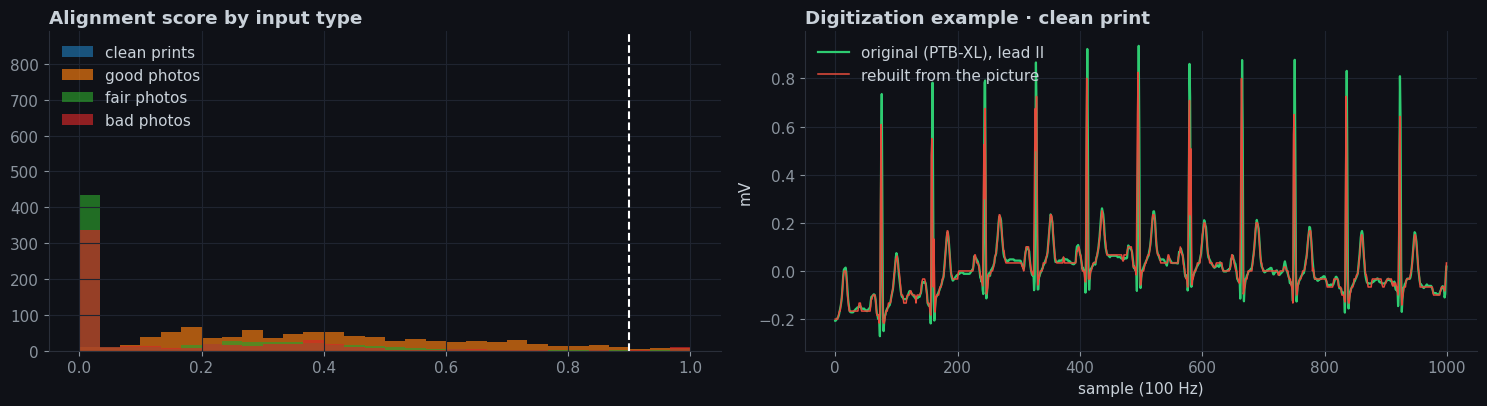

In [20]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 16  ·  Digitizer: printout → waveforms   ║
# ╚══════════════════════════════════════════════════════════╝
from multiprocessing import Pool
from tqdm.auto import tqdm

banner('Step 7 · Digitization', 'Tracing the pen line of every lead and rebuilding millivolt signals from the picture')

BAND, NS = 58, 250                                        # search half-height (px) · samples per 2.5 s window
ROW_YC   = [int(Y0 + (r + .5) * ROW_H) for r in range(4)]  # baselines of the 3 lead rows + the rhythm strip

def rectify(img):
    """Resize to the canonical 800x400 page."""
    return (cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA) if img.shape[:2] != (H, W) else img), 1.0

def ink_map(img):
    """1 where the pen ink is, 0 on paper/grid. Illumination-normalised so shadows do not matter."""
    mx = img.max(2).astype(np.float32)                         # grid lines are bright in at least one channel, ink is dark in all
    bg = cv2.GaussianBlur(cv2.dilate(mx, np.ones((11, 11), np.uint8)), (0, 0), 12)
    n  = mx / np.maximum(bg, 1.0)
    return (n < 0.62).astype(np.uint8)

def trace_window(ink, xs, yc, nsamp):
    """Follow the waveform column by column. Returns y (pixels) per sample and the fraction of columns found."""
    ncol = int(round(nsamp * PXS)); ys = np.full(ncol, np.nan); prev = float(yc)
    lo = max(0, int(yc - BAND)); hi = min(ink.shape[0], int(yc + BAND))
    for j in range(ncol):
        x = int(round(xs)) + j
        if x >= ink.shape[1]: break
        idx = np.flatnonzero(ink[lo:hi, x])
        if idx.size == 0: continue
        runs = np.split(idx, np.flatnonzero(np.diff(idx) > 2) + 1)
        def dist(r):
            a, b = r[0] + lo, r[-1] + lo
            return 0 if a <= prev <= b else min(abs(a - prev), abs(b - prev))
        r = min(runs, key=dist); top, bot = r[0] + lo, r[-1] + lo
        y = (top + bot) / 2 if bot - top <= 3 else (top if abs(top - prev) > abs(bot - prev) else bot)   # thin line → centre · steep stroke → far end (keeps peaks)
        ys[j] = y; prev = y
    ok = ~np.isnan(ys)
    if ok.sum() < 0.3 * ncol: return None, float(ok.mean())
    col = np.interp(np.arange(ncol), np.flatnonzero(ok), ys[ok])
    return np.interp(np.arange(nsamp) * PXS, np.arange(ncol), col), float(ok.mean())   # sample k sits at column k * PXS

def _cal_masks():
    m, z = np.zeros((H, W), np.uint8), np.zeros((H, W), np.uint8)
    for r in range(4):
        yc = ROW_YC[r]
        cv2.polylines(m, [np.array([[6, yc], [11, yc], [11, yc - MV], [26, yc - MV], [26, yc], [31, yc]], np.int32)], False, 1, 5)
        z[yc - MV - 8: yc + 8, 0:38] = 1
    return m.astype(bool), z.astype(bool)
CAL_MASK, CAL_ZONE = _cal_masks()

def digitize(photo):
    """photo (BGR) -> dict(sig=(1000,12) mV with NaN where the printout shows nothing, conf, align)."""
    page, reg = rectify(photo)
    ink = ink_map(page)
    align = float(ink[CAL_MASK].sum() / (ink[CAL_ZONE].sum() + 1e-6))                        # ~1 if the page sits exactly on the template, ~0 if shifted/tilted/blurred
    sig = np.full((1000, 12), np.nan, np.float32); covs = []
    for r in range(3):
        for c in range(4):
            li = LAYOUT[r][c]
            y, cov = trace_window(ink, X0 + c * NS * PXS, ROW_YC[r], NS); covs.append(cov)
            if y is not None: sig[c * NS:(c + 1) * NS, li] = (ROW_YC[r] - y) / MV
    y, cov = trace_window(ink, X0, ROW_YC[3], 1000); covs.append(cov)       # 10 s rhythm strip = full lead II
    if y is not None: sig[:, 1] = (ROW_YC[3] - y) / MV
    return dict(sig=sig, conf=float(np.mean(covs)), align=align, page=page)

def layout_mask(sig):
    """What a printed 12-lead ECG actually shows: each lead only inside its 2.5 s window, lead II for the full 10 s."""
    out = np.full_like(sig, np.nan)
    for r in range(3):
        for c in range(4):
            li = LAYOUT[r][c]; out[c * NS:(c + 1) * NS, li] = sig[c * NS:(c + 1) * NS, li]
    out[:, 1] = sig[:, 1]
    return out

IMG_DIR = '/content/isoline_imgs'
VT = np.concatenate([ROWS['val'], ROWS['test']]); NV = len(ROWS['val'])

def dig_file(fn):
    d = digitize(cv2.imread(f'{IMG_DIR}/{fn}'))
    return d['sig'].astype(np.float16), d['conf'], d['align']

t0 = time.time()
with Pool(max(1, os.cpu_count())) as pool:
    outs = list(tqdm(pool.imap(dig_file, man.file.values[VT], chunksize=16), total=len(VT), desc='Digitising'))
SIG_D  = np.stack([o[0] for o in outs]); CONF_D = np.array([o[1] for o in outs]); ALIGN_D = np.array([o[2] for o in outs])
print(f'{len(VT):,} images digitised in {time.time()-t0:.0f}s')

# how close is the rebuilt signal to the original PTB-XL signal? (correlation, only over what the printout shows)
X_RAWD = np.load(f"{DIRS['data']}/X.npy", mmap_mode='r')
def _corr(a, b):
    m = ~np.isnan(a)
    if m.sum() < 50: return np.nan
    a, b = a[m] - a[m].mean(), b[m] - b[m].mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-9))
def _truth(sig): return layout_mask(np.clip(sig - np.median(sig, 0), -2.5, 2.5))
CORR_D = np.array([np.nanmean([_corr(SIG_D[j][:, l].astype(np.float32), tr[:, l]) for l in range(12)])
                   for j, tr in ((j, _truth(np.asarray(X_RAWD[man.idx.values[VT[j]]], np.float32))) for j in range(len(VT)))])

TAU = 0.9 * float(np.percentile(ALIGN_D[:NV][KIND[ROWS['val']] == 'clean'], 5))      # trust threshold: chosen on VAL clean prints only
Kt_, Qt_ = KIND[ROWS['test']], LAB_Q[ROWS['test']]
al_t, co_t = ALIGN_D[NV:], CORR_D[NV:]
groups = {'clean prints': Kt_ == 'clean', 'good photos': (Kt_ == 'photo') & (Qt_ == 0),
          'fair photos': (Kt_ == 'photo') & (Qt_ == 1), 'bad photos': (Kt_ == 'photo') & (Qt_ == 2)}
tab = pd.DataFrame({g: dict(n=int(m.sum()), alignment_median=np.median(al_t[m]), pct_trusted=100 * np.mean(al_t[m] >= TAU),
                            recon_corr_all=np.nanmean(co_t[m]), recon_corr_trusted=np.nanmean(co_t[m & (al_t >= TAU)]) if (m & (al_t >= TAU)).any() else np.nan)
                    for g, m in groups.items()}).T
print(f'\nTrust threshold on alignment (from validation clean prints): {TAU:.2f}')
print(tab.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for g, m in groups.items(): ax[0].hist(al_t[m], bins=30, alpha=.65, label=g)
ax[0].axvline(TAU, color='w', ls='--'); ax[0].set_title('Alignment score by input type', loc='left', fontweight='bold'); ax[0].legend(frameon=False)
ex = int(np.where(groups['clean prints'] & (al_t >= TAU))[0][4])
tr = _truth(np.asarray(X_RAWD[man.idx.values[ROWS['test'][ex]]], np.float32))
ax[1].plot(tr[:, 1], color='#2ecc71', lw=1.6, label='original (PTB-XL), lead II'); ax[1].plot(SIG_D[NV + ex][:, 1].astype(np.float32), color='#e74c3c', lw=1.1, label='rebuilt from the picture')
ax[1].legend(frameon=False); ax[1].set_title('Digitization example · clean print', loc='left', fontweight='bold'); ax[1].set_xlabel('sample (100 Hz)'); ax[1].set_ylabel('mV')
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/digitization_results.png", dpi=150); plt.show()
json.dump({'tau': TAU, 'table': tab.round(4).to_dict()}, open(f"{DIRS['results']}/digitization_metrics.json", 'w'), indent=2)

                           outcome    n share top1_accuracy
                          reliable  984 22.8%         89.6%
         flagged (models disagree) 1201 27.8%         52.6%
image-only (signal path untrusted) 1596 37.0%         82.0%
       rejected (retake the image)  535 12.4%         77.4%

Image model alone, answering every image: top-1 accuracy 82.4%
Isoline, answers only when not rejected : top-1 accuracy 74.6%  (answers 87.6% of inputs)
Isoline, "reliable" answers only        : top-1 accuracy 89.6%  (covers 22.8% of inputs)

On clean prints  ->  image AUC 0.929 | rebuilt-signal AUC 0.814 | fused AUC 0.913
(original-signal models on the full 10 s: 0.929 · on printout-style signals: see Cell 15)


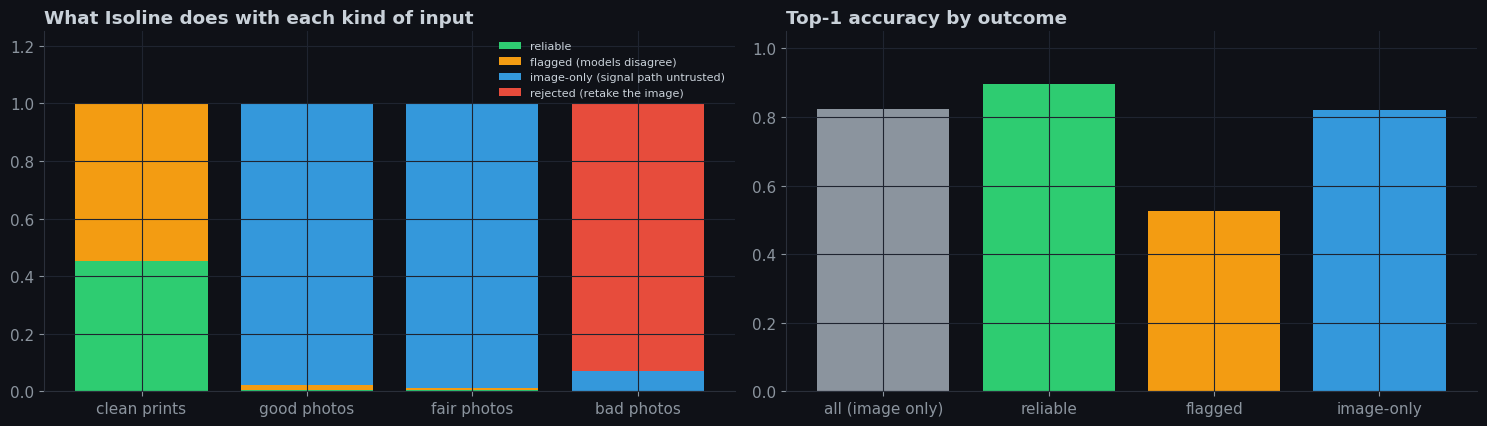

In [21]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 17  ·  Reliability engine (the decision) ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 8 · Reliability', 'Quality gate + alignment + two-model agreement decide: answer, flag, or ask for a better image')

# --- signal model reads the rebuilt waveforms ---
def to_input(S):
    S = S.astype(np.float32); S = S - np.nanmedian(S, axis=1, keepdims=True)
    return torch.tensor((np.clip(np.nan_to_num(S), -2.5, 2.5).transpose(0, 2, 1) / std).astype(np.float32), device=device)
@torch.no_grad()
def run_sig(Sd, bs=256):
    lmodel.eval(); out = []
    for i in range(0, len(Sd), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(lmodel(to_input(Sd[i:i + bs])).float().cpu())
    return torch.cat(out).numpy()
p_sig = sigm(run_sig(SIG_D[NV:]))                                  # (test rows, 5)

# --- the decision rules (pure numpy, easy to read and to deploy) ---
def decide(p_img, p_sig, qual_pred, align, tau):
    """Returns (outcome, fused probabilities). outcome: 0 reliable · 1 flagged: models disagree · 2 image-only: signal path untrusted · 3 rejected: ask for better image"""
    n = len(p_img); out = np.zeros(n, int); fused = p_img.copy()
    trusted = align >= tau
    agree = p_img.argmax(1) == p_sig.argmax(1)
    out[trusted & agree] = 0
    out[trusted & ~agree] = 1
    out[~trusted] = 2
    fused[trusted] = (p_img[trusted] + p_sig[trusted]) / 2
    out[qual_pred == 2] = 3                                         # quality gate says "bad" -> never answer
    return out, fused
NAMES_OUT = ['reliable', 'flagged (models disagree)', 'image-only (signal path untrusted)', 'rejected (retake the image)']

qual_pred = np.load(f"{DIRS['results']}/image_test_outputs.npz")['qual_prob'].argmax(1)
outcome, fused = decide(pt_img, p_sig, qual_pred, al_t, TAU)
top1 = fused.argmax(1); correct = Yt[np.arange(len(Yt)), top1] == 1                   # top-1 prediction is one of the patient's true labels
base_acc = float((Yt[np.arange(len(Yt)), pt_img.argmax(1)] == 1).mean())

rows = []
for o in range(4):
    m = outcome == o
    rows.append(dict(outcome=NAMES_OUT[o], n=int(m.sum()), share=f'{m.mean():.1%}', top1_accuracy=f'{correct[m].mean():.1%}' if m.any() else '-'))
print(pd.DataFrame(rows).to_string(index=False))
ans = outcome < 3
print(f'\nImage model alone, answering every image: top-1 accuracy {base_acc:.1%}')
print(f'Isoline, answers only when not rejected : top-1 accuracy {correct[ans].mean():.1%}  (answers {ans.mean():.1%} of inputs)')
print(f'Isoline, "reliable" answers only        : top-1 accuracy {correct[outcome == 0].mean():.1%}  (covers {np.mean(outcome == 0):.1%} of inputs)')

def _auc(Y, P):
    try: return float(roc_auc_score(Y, P, average='macro'))
    except Exception: return float('nan')
cl = groups['clean prints']
print(f"\nOn clean prints  ->  image AUC {_auc(Yt[cl], pt_img[cl]):.3f} | rebuilt-signal AUC {_auc(Yt[cl], p_sig[cl]):.3f} | fused AUC {_auc(Yt[cl], fused[cl]):.3f}")
print('(original-signal models on the full 10 s: 0.929 · on printout-style signals: see Cell 15)')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4)); cols = ['#2ecc71', '#f39c12', '#3498db', '#e74c3c']
bottom = np.zeros(4)
for o in range(4):
    v = np.array([np.mean(outcome[m] == o) for m in groups.values()]); ax[0].bar(list(groups), v, bottom=bottom, color=cols[o], label=NAMES_OUT[o]); bottom += v
ax[0].set_title('What Isoline does with each kind of input', loc='left', fontweight='bold'); ax[0].legend(frameon=False, fontsize=8, loc='upper right'); ax[0].set_ylim(0, 1.25)
acc_o = [correct[outcome == o].mean() if (outcome == o).any() else 0 for o in range(4)]
ax[1].bar(['all (image only)', 'reliable', 'flagged', 'image-only'], [base_acc, acc_o[0], acc_o[1], acc_o[2]], color=['#8b949e', cols[0], cols[1], cols[2]])
ax[1].set_ylim(0, 1.05); ax[1].set_title('Top-1 accuracy by outcome', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/reliability_results.png", dpi=150); plt.show()
json.dump({'tau': TAU, 'outcomes': rows, 'image_only_top1': base_acc, 'answered_top1': float(correct[ans].mean()),
           'reliable_top1': float(correct[outcome == 0].mean()) if (outcome == 0).any() else None},
          open(f"{DIRS['results']}/reliability_metrics.json", 'w'), indent=2)

                           outcome    n share image_top1_accuracy
                          reliable  984 22.8%               89.6%
         flagged (models disagree) 1201 27.8%               79.1%
image-only (signal path untrusted) 1596 37.0%               82.0%
       rejected (retake the image)  535 12.4%               77.8%

policy                                                answers  top-1 acc
A · answer every image                                 100.0%      82.4%
B · answer unless the quality gate rejects              87.6%      83.0%
C · B, but withhold when the two models disagree        59.8%      84.9%
D · answer only when both models agree                  22.8%      89.6%


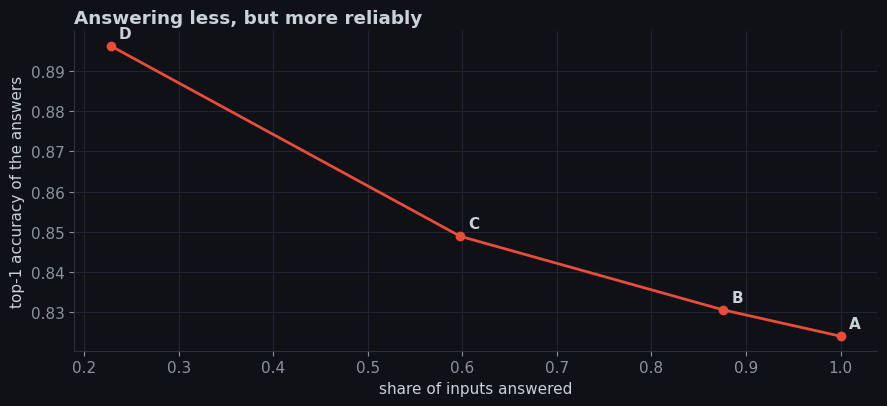

In [22]:
# ╔══════════════════════════════════════════════════════════╗
# ║  ISOLINE  ·  Cell 18  ·  Final decision policy            ║
# ║  The image model answers; the signal path is a cross-check ║
# ╚══════════════════════════════════════════════════════════╝
banner('Step 8 · Final policy', 'Fusing probabilities hurt (rebuilt-signal path is weaker), so agreement is used as a trust signal instead')

outcome, _ = decide(pt_img, p_sig, qual_pred, al_t, TAU)          # same four outcomes as Cell 17
hit = Yt[np.arange(len(Yt)), pt_img.argmax(1)] == 1                # the image model's top-1 is one of the true labels
n_all = len(hit)

rows = []
for o in range(4):
    m = outcome == o
    rows.append(dict(outcome=NAMES_OUT[o], n=int(m.sum()), share=f'{m.mean():.1%}', image_top1_accuracy=f'{hit[m].mean():.1%}' if m.any() else '-'))
print(pd.DataFrame(rows).to_string(index=False))

policies = {
    'A · answer every image':                         np.ones(n_all, bool),
    'B · answer unless the quality gate rejects':     outcome != 3,
    'C · B, but withhold when the two models disagree': (outcome == 0) | (outcome == 2),
    'D · answer only when both models agree':         outcome == 0,
}
print(f"\n{'policy':<52}{'answers':>9}{'top-1 acc':>11}")
res = {}
for k, m in policies.items():
    res[k] = (float(m.mean()), float(hit[m].mean())); print(f'{k:<52}{m.mean():>9.1%}{hit[m].mean():>11.1%}')

fig, ax = plt.subplots(figsize=(9, 4.2))
xs, ys = [v[0] for v in res.values()], [v[1] for v in res.values()]
ax.plot(xs, ys, '-o', color='#e74c3c', lw=2)
for k, x, y in zip(res, xs, ys): ax.annotate(k[0], (x, y), textcoords='offset points', xytext=(6, 6), fontweight='bold')
ax.set_xlabel('share of inputs answered'); ax.set_ylabel('top-1 accuracy of the answers'); ax.set_title('Answering less, but more reliably', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{DIRS['results']}/policy_tradeoff.png", dpi=150); plt.show()
json.dump({'tau': TAU, 'outcomes': rows, 'policies': {k: dict(answered=v[0], top1=v[1]) for k, v in res.items()}},
          open(f"{DIRS['results']}/final_policy_metrics.json", 'w'), indent=2)

In [ ]:
import os, json, zipfile
from google.colab import files, drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

print('Pick isoline-ecg.zip (the LAST one I sent) ...')
up = files.upload()
zip_name = list(up)[-1]
!rm -rf /content/isoline-ecg
with zipfile.ZipFile(zip_name) as z:
    z.extractall('/content')
%cd /content/isoline-ecg

# 1) copy weights, results and example pictures from Drive
!python scripts/prepare_release.py --drive /content/drive/MyDrive/isoline --images /content/isoline_imgs

# 2) keep this notebook inside the repo
try:
    from google.colab import _message
    nb = _message.blocking_request('get_ipynb', request='', timeout_sec=240)['ipynb']
    os.makedirs('notebooks', exist_ok=True)
    json.dump(nb, open('notebooks/isoline_training.ipynb', 'w'))
    print('Saved notebooks/isoline_training.ipynb')
except Exception as e:
    print('Could not save the notebook automatically:', e)
    print('By hand: File > Download > .ipynb, then upload it to the notebooks folder on GitHub.')

# 3) test everything with the REAL weights
!python evaluate.py
!python predict.py --image samples/ecg_01.jpg --report /content/test_report.html

# 4) build the website + README, check file sizes
!python scripts/build_site.py
!du -sh weights/* site
big = [f for f in os.listdir('weights') if os.path.getsize('weights/' + f) > 95e6]
print('Files too big for GitHub:', big or 'none')

Pick isoline-ecg.zip (the LAST one I sent) ...


Saving isoline-ecg.zip to isoline-ecg.zip
/content/isoline-ecg
  weights/isoline_image_net.pt  (16.4 MB)
  weights/isoline_signal_net_layout.pt  (15.2 MB)
  weights/isoline_signal_net.pt  (15.2 MB)
  weights/signal_norm.npz  (0.0 MB)
  weights/calibration.json
  results/dataset_stats.json  (21388 records, 42776 pictures)
  samples/  11 pictures + labels.csv (random draw from the test split, seed 7)
Done. Next: python evaluate.py
